# Capstone 2: Cleaning Messy Sales Data with SQL & Python

**Student:** Pretty Mpanza  
**Dataset:** `dirty_cafe_sales.csv` (10,000 café transactions, 8 columns)

## Executive Overview

Café leadership requires reliable product and regional insights to drive business strategy. However, the raw sales export is currently unreliable due to multiple data quality defects: missing values are disguised across blanks, `ERROR`, and `UNKNOWN` tokens; numeric amounts and dates are incorrectly stored as raw text.

This notebook executes a robust end-to-end data pipeline, transitioning the raw export into a fully validated, analysis-ready structure. The solution follows the five core steps mandated by the brief:

1. **Find the problems:** Inspect the raw dataset and establish an Issue Register with rigorous SQL detection queries.
2. **Standardise with reference tables:** Create small lookup dimension tables to normalize categories cleanly.
3. **Produce a clean analysis table:** Enforce correct data types, consistent category mappings, deduplication, and intelligent single-field numeric recovery.
4. **Validate automatically:** Execute automated assertion checks and generate a comprehensive validation report.
5. **Explain the choices:** Summarize applied fixes, strategic insights, and residual risks for leadership.

## Setup: project paths

This section sets the project root, the location of the raw CSV and the path of the SQLite database used by the rest of the notebook.

In [3]:
from pathlib import Path
import sqlite3
import pandas as pd
import os

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "sql").exists() and (PROJECT_ROOT.parent / "sql").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "dirty_cafe_sales.csv"
if not DATA_PATH.exists():
    DATA_PATH = Path('/content/dirty_cafe_sales.csv')

DB_PATH = PROJECT_ROOT / "data" / "cafe_sales.db"
DB_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Raw CSV exists:", DATA_PATH.exists())
print("Database Path:", DB_PATH)



Project Root: /content
Raw CSV exists: True
Database Path: /content/data/cafe_sales.db


**Result.** The project root and the raw CSV were located, and the database path was set. No data has been modified at this point.

## Step 1a. Raw data inspection

**Purpose.** To review the export exactly as received. All columns are read as text (`dtype=str`), so no value is converted or altered on import.

In [4]:

df_raw = pd.read_csv(DATA_PATH, dtype=str)
print("Raw Dataset Shape:", df_raw.shape)
display(df_raw.head(10))

print("\n--- Raw Missing Values (Pandas View) ---")
display(df_raw.isna().sum().to_frame("null_count"))

Raw Dataset Shape: (10000, 8)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31



--- Raw Missing Values (Pandas View) ---


,null_count
Transaction ID,0
Item,333
Quantity,138
Price Per Unit,179
Total Spent,173
Payment Method,2579
Location,3265
Transaction Date,159


**Findings.** The sample rows already show the main defects. `TXN_4271903` has `ERROR` in Total Spent, and `TXN_7034554` has `UNKNOWN` in both Payment Method and Location.

Pandas reports these blank counts: Item 333, Quantity 138, Price Per Unit 179, Total Spent 173, Payment Method 2,579, Location 3,265 and Transaction Date 159. These figures understate the problem, because `ERROR` and `UNKNOWN` are ordinary text and are not counted as missing.

## Step 1b. Issue Register

Six issue groups were identified. Issues 1 to 5 are defects in the data. Issue 6 records checks that found no problem, so that their absence is documented.

| ID | Issue | Columns | Evidence |
|---|---|---|---|
| 1 | Inconsistent representation of missing values (blank, `NULL`, `ERROR`, `UNKNOWN`) | All columns except Transaction ID | 10,082 unusable values across 6,911 rows |
| 2 | Invalid category values mixed with valid ones | Item, Payment Method, Location | 636 / 599 / 696 `ERROR` or `UNKNOWN` values |
| 3 | Numeric columns stored as text, containing non-numeric tokens | Quantity, Price Per Unit, Total Spent | 341 / 354 / 329 non-numeric values |
| 4 | Dates stored as text, containing placeholder values | Transaction Date | 301 placeholder values plus 159 blanks |
| 5 | High proportion of unusable values | Location, Payment Method | 39.6% and 31.8% of rows |
| 6 | Checks with no findings: duplicate IDs, spelling or case variants, arithmetic errors | Transaction ID, categories, amounts | None found |

Issue 6 matters for the cleaning approach. Quantity × Price equals Total on every row where all three values are present, so a single missing amount can be derived rather than treated as unknown.

**Purpose of the next cell.** The raw data is loaded into a staging table in SQLite, and two detection queries measure the issues directly: placeholder values in `Item` (issues 1 and 2) and non-numeric tokens in the three numeric columns (issue 3). Figures for the remaining columns in the table above come from equivalent queries.

In [5]:
# Run detection queries against SQLite staging
conn = sqlite3.connect(DB_PATH)

# Ingest into staging table
df_raw.to_sql("staging_cafe_sales", conn, if_exists="replace", index=False)

# Detection Query 1: Placeholders
q1 = '''
SELECT
    'Item' AS column_name,
    SUM(CASE WHEN Item IS NULL OR TRIM(Item) = '' THEN 1 ELSE 0 END) AS blank_or_null,
    SUM(CASE WHEN UPPER(TRIM(Item)) IN ('ERROR', 'UNKNOWN') THEN 1 ELSE 0 END) AS placeholder_count
FROM staging_cafe_sales
'''
print("--- Issue 1: Placeholders Check ---")
display(pd.read_sql_query(q1, conn))

# Detection Query 3: Non-numeric tokens in Quantity/Price/Total
q3 = '''
SELECT
    SUM(CASE WHEN Quantity GLOB '*[^0-9]*' AND TRIM(Quantity) != '' THEN 1 ELSE 0 END) AS non_numeric_quantity,
    SUM(CASE WHEN [Price Per Unit] GLOB '*[^0-9.]*' AND TRIM([Price Per Unit]) != '' THEN 1 ELSE 0 END) AS non_numeric_price,
    SUM(CASE WHEN [Total Spent] GLOB '*[^0-9.]*' AND TRIM([Total Spent]) != '' THEN 1 ELSE 0 END) AS non_numeric_total
FROM staging_cafe_sales
'''
print("--- Issue 3: Non-numeric Tokens ---")
display(pd.read_sql_query(q3, conn))

conn.close()



--- Issue 1: Placeholders Check ---


,column_name,blank_or_null,placeholder_count
0,Item,333,636


--- Issue 3: Non-numeric Tokens ---


,non_numeric_quantity,non_numeric_price,non_numeric_total
0,341,354,329


**Findings.** In `Item` the query finds 333 blank values and 636 placeholders (292 `ERROR` and 344 `UNKNOWN`), so 969 of 10,000 values are unusable. Loading through pandas stores the blanks as `NULL`, while `ERROR` and `UNKNOWN` remain as text, which is why they need separate handling.

The numeric columns contain 341 non-numeric quantities, 354 non-numeric prices and 329 non-numeric totals.

## Step 2. Standardise with reference tables

**Purpose.** To keep the allowed values in small lookup tables rather than in long `CASE` chains inside the cleaning query. The query joins to these tables, so a category can be added or changed with a single `INSERT`.

Four tables are created: `placeholder_reference` (values treated as "no value"), `item_reference`, `payment_method_reference` and `location_reference` (the allowed categories).

In [6]:
conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

# Reference SQL script execution
ref_sql = '''
DROP TABLE IF EXISTS placeholder_reference;
CREATE TABLE placeholder_reference (raw_value TEXT PRIMARY KEY, cleaned_value TEXT);
INSERT INTO placeholder_reference VALUES
('', NULL), ('UNKNOWN', NULL), ('ERROR', NULL);

DROP TABLE IF EXISTS item_reference;
CREATE TABLE item_reference (item_name TEXT PRIMARY KEY);
INSERT INTO item_reference VALUES ('Cake'), ('Coffee'), ('Cookie'), ('Juice'), ('Salad'), ('Sandwich'), ('Smoothie'), ('Tea');

DROP TABLE IF EXISTS payment_method_reference;
CREATE TABLE payment_method_reference (payment_method TEXT PRIMARY KEY);
INSERT INTO payment_method_reference VALUES ('Cash'), ('Credit Card'), ('Digital Wallet');

DROP TABLE IF EXISTS location_reference;
CREATE TABLE location_reference (location_name TEXT PRIMARY KEY);
INSERT INTO location_reference VALUES ('In-store'), ('Takeaway'), ('Drive-thru');
'''

cursor.executescript(ref_sql)
conn.commit()

print("Reference tables successfully created and populated.")
display(pd.read_sql_query("SELECT * FROM item_reference", conn))
conn.close()



Reference tables successfully created and populated.


,item_name
0,Cake
1,Coffee
2,Cookie
3,Juice
4,Salad
5,Sandwich
6,Smoothie
7,Tea


**Findings.** The tables are created and populated. `item_reference` contains the eight menu items: Cake, Coffee, Cookie, Juice, Salad, Sandwich, Smoothie and Tea.

In the cleaning query, each raw value is matched to the allowed list, ignoring capitalisation and surrounding spaces. A matching value is kept. A value that does not match, such as `ERROR` or `UNKNOWN`, becomes `NULL`.

`location_reference` also lists `Drive-thru`. It is permitted but does not occur in this dataset, which contains only In-store and Takeaway.

## Step 3. Clean analysis table

**Purpose.** To build one analysis table, `cleaned_cafe_sales`, with explicit data types, a primary key on `transaction_id` and `CHECK` constraints that reject non-positive quantities and negative amounts. Because the key is unique, duplicate transaction IDs would be rejected.

**Recovery of missing amounts.** Where exactly one of Quantity, Price Per Unit and Total Spent is missing and the other two are valid, the missing value is calculated from the relationship Quantity × Price = Total. Each calculated value is flagged in `numeric_value_was_derived`, and `derived_field` records which field was filled.

In [7]:
conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

clean_ddl_and_transform = '''
DROP TABLE IF EXISTS cleaned_cafe_sales;

CREATE TABLE cleaned_cafe_sales (
    transaction_id TEXT PRIMARY KEY,
    transaction_date TEXT,
    item TEXT,
    quantity INTEGER,
    price_per_unit REAL,
    total_spent REAL,
    payment_method TEXT,
    location TEXT,
    numeric_value_was_derived INTEGER DEFAULT 0,
    derived_field TEXT,
    CHECK (quantity IS NULL OR quantity > 0),
    CHECK (price_per_unit IS NULL OR price_per_unit >= 0),
    CHECK (total_spent IS NULL OR total_spent >= 0)
);

INSERT INTO cleaned_cafe_sales
SELECT
    s.[Transaction ID] AS transaction_id,
    CASE
        WHEN s.[Transaction Date] GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'
         AND date(s.[Transaction Date]) IS NOT NULL
         AND date(s.[Transaction Date]) = s.[Transaction Date]
        THEN s.[Transaction Date]
        ELSE NULL
    END AS transaction_date,
    CASE WHEN pr_item.raw_value IS NOT NULL THEN NULL ELSE ir.item_name END AS item,

    CAST(
        CASE
            WHEN s.Quantity GLOB '[0-9]*' AND TRIM(s.Quantity) != '' THEN s.Quantity
            WHEN (s.Quantity IS NULL OR s.Quantity NOT GLOB '[0-9]*')
                 AND s.[Total Spent] GLOB '[0-9]*.[0-9]*' AND s.[Price Per Unit] GLOB '[0-9]*.[0-9]*'
                 AND CAST(s.[Price Per Unit] AS REAL) > 0
            THEN ROUND(CAST(s.[Total Spent] AS REAL) / CAST(s.[Price Per Unit] AS REAL))
            ELSE NULL
        END AS INTEGER
    ) AS quantity,

    CAST(
        CASE
            WHEN s.[Price Per Unit] GLOB '[0-9]*.[0-9]*' AND TRIM(s.[Price Per Unit]) != '' THEN s.[Price Per Unit]
            WHEN (s.[Price Per Unit] IS NULL OR s.[Price Per Unit] NOT GLOB '[0-9]*.[0-9]*')
                 AND s.[Total Spent] GLOB '[0-9]*.[0-9]*' AND s.Quantity GLOB '[0-9]*'
                 AND CAST(s.Quantity AS REAL) > 0
            THEN ROUND(CAST(s.[Total Spent] AS REAL) / CAST(s.Quantity AS REAL), 2)
            ELSE NULL
        END AS REAL
    ) AS price_per_unit,

    CAST(
        CASE
            WHEN s.[Total Spent] GLOB '[0-9]*.[0-9]*' AND TRIM(s.[Total Spent]) != '' THEN s.[Total Spent]
            WHEN (s.[Total Spent] IS NULL OR s.[Total Spent] NOT GLOB '[0-9]*.[0-9]*')
                 AND s.Quantity GLOB '[0-9]*' AND s.[Price Per Unit] GLOB '[0-9]*.[0-9]*'
            THEN ROUND(CAST(s.Quantity AS REAL) * CAST(s.[Price Per Unit] AS REAL), 2)
            ELSE NULL
        END AS REAL
    ) AS total_spent,

    CASE WHEN pr_payment.raw_value IS NOT NULL THEN NULL ELSE pmr.payment_method END AS payment_method,
    CASE WHEN pr_location.raw_value IS NOT NULL THEN NULL ELSE lr.location_name END AS location,

    CASE
        WHEN (s.Quantity IS NULL OR s.Quantity NOT GLOB '[0-9]*') AND s.[Total Spent] GLOB '[0-9]*' AND s.[Price Per Unit] GLOB '[0-9]*' THEN 1
        WHEN (s.[Price Per Unit] IS NULL OR s.[Price Per Unit] NOT GLOB '[0-9]*') AND s.[Total Spent] GLOB '[0-9]*' AND s.Quantity GLOB '[0-9]*' THEN 1
        WHEN (s.[Total Spent] IS NULL OR s.[Total Spent] NOT GLOB '[0-9]*') AND s.Quantity GLOB '[0-9]*' AND s.[Price Per Unit] GLOB '[0-9]*' THEN 1
        ELSE 0
    END AS numeric_value_was_derived,

    CASE
        WHEN (s.Quantity IS NULL OR s.Quantity NOT GLOB '[0-9]*') AND s.[Total Spent] GLOB '[0-9]*' AND s.[Price Per Unit] GLOB '[0-9]*' THEN 'quantity'
        WHEN (s.[Price Per Unit] IS NULL OR s.[Price Per Unit] NOT GLOB '[0-9]*') AND s.[Total Spent] GLOB '[0-9]*' AND s.Quantity GLOB '[0-9]*' THEN 'price_per_unit'
        WHEN (s.[Total Spent] IS NULL OR s.[Total Spent] NOT GLOB '[0-9]*') AND s.Quantity GLOB '[0-9]*' AND s.[Price Per Unit] GLOB '[0-9]*' THEN 'total_spent'
        ELSE NULL
    END AS derived_field

FROM staging_cafe_sales s
LEFT JOIN placeholder_reference pr_item
    ON COALESCE(UPPER(TRIM(s.Item)), '') = UPPER(pr_item.raw_value)
LEFT JOIN placeholder_reference pr_payment
    ON COALESCE(UPPER(TRIM(s.[Payment Method])), '') = UPPER(pr_payment.raw_value)
LEFT JOIN placeholder_reference pr_location
    ON COALESCE(UPPER(TRIM(s.Location)), '') = UPPER(pr_location.raw_value)
LEFT JOIN item_reference ir ON UPPER(TRIM(s.Item)) = UPPER(ir.item_name)
LEFT JOIN payment_method_reference pmr ON UPPER(TRIM(s.[Payment Method])) = UPPER(pmr.payment_method)
LEFT JOIN location_reference lr ON UPPER(TRIM(s.Location)) = UPPER(lr.location_name);
'''

cursor.executescript(clean_ddl_and_transform)
conn.commit()

df_clean = pd.read_sql_query("SELECT * FROM cleaned_cafe_sales", conn)
print("Cleaned Table Shape:", df_clean.shape)
display(df_clean.head(10))

# Export the cleaned analysis table for Excel and Power BI
export_dir = PROJECT_ROOT / "data" / "processed"
export_dir.mkdir(parents=True, exist_ok=True)
clean_csv_path = export_dir / "cleaned_cafe_sales.csv"
df_clean.to_csv(clean_csv_path, index=False, encoding="utf-8-sig")
print("Cleaned CSV exported:", clean_csv_path)
print("Exported rows:", len(df_clean))

conn.close()



Cleaned Table Shape: (10000, 10)


,transaction_id,transaction_date,item,quantity,price_per_unit,total_spent,payment_method,location,numeric_value_was_derived,derived_field
0,TXN_1961373,2023-09-08,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,0,None
1,TXN_4977031,2023-05-16,Cake,4.0,3.0,12.0,Cash,In-store,0,None
2,TXN_4271903,2023-07-19,Cookie,4.0,1.0,4.0,Credit Card,In-store,1,total_spent
3,TXN_7034554,2023-04-27,Salad,2.0,5.0,10.0,None,None,0,None
4,TXN_3160411,2023-06-11,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,0,None
5,TXN_2602893,2023-03-31,Smoothie,5.0,4.0,20.0,Credit Card,None,0,None
6,TXN_4433211,2023-10-06,None,3.0,3.0,9.0,None,Takeaway,0,None
7,TXN_6699534,2023-10-28,Sandwich,4.0,4.0,16.0,Cash,None,0,None
8,TXN_4717867,2023-07-28,None,5.0,3.0,15.0,None,Takeaway,0,None
9,TXN_2064365,2023-12-31,Sandwich,5.0,4.0,20.0,None,In-store,0,None


Cleaned CSV exported: /content/data/processed/cleaned_cafe_sales.csv
Exported rows: 10000


**Findings.** The clean table holds all 10,000 rows in 10 columns, with no rows lost. Before and after examples from the output:

| Transaction | Raw values | Clean values | Explanation |
|---|---|---|---|
| `TXN_4271903` | Total Spent = `ERROR` | Total Spent = 4.0, flagged `total_spent` | 4 × 1.00 = 4.00, so the total was derived |
| `TXN_7034554` | Payment Method and Location = `UNKNOWN` | Both `NULL` | No other column contains this information |
| `TXN_4433211` | Item = `UNKNOWN`, Payment Method = `ERROR` | Both `NULL` | Placeholders are not valid categories |

Values that cannot be reconstructed remain `NULL`: 969 items, 3,178 payment methods, 3,961 locations and 460 dates. A further 38 quantities, 38 prices and 40 totals remain `NULL` because those rows are missing two of the three amounts, which is not enough to calculate either.

## Step 4. Automated validation

**Purpose.** To test the cleaned table with six assertion-based checks. The checks cover row retention, transaction-key uniqueness, arithmetic consistency, non-null keys, allowed category values and valid populated dates. A failed assertion stops the notebook. The validation summary is saved as `reports/validation_report.csv`.

In [8]:
conn = sqlite3.connect(DB_PATH)

# Check 1: Row retention
count_check = pd.read_sql_query(
    "SELECT COUNT(*) AS total_rows FROM cleaned_cafe_sales", conn
).iloc[0]["total_rows"]
assert count_check == 10000, f"FAILED: Expected 10,000 rows, found {count_check}"
print("✓ Check 1 Passed: All 10,000 rows retained.")

# Check 2: Transaction ID uniqueness
unique_check = pd.read_sql_query(
    "SELECT COUNT(DISTINCT transaction_id) AS unique_ids FROM cleaned_cafe_sales", conn
).iloc[0]["unique_ids"]
assert unique_check == 10000, f"FAILED: Expected 10,000 unique IDs, found {unique_check}"
print("✓ Check 2 Passed: Transaction IDs are unique.")

# Check 3: Arithmetic consistency
math_mismatch = pd.read_sql_query("""
    SELECT COUNT(*) AS mismatches
    FROM cleaned_cafe_sales
    WHERE quantity IS NOT NULL
      AND price_per_unit IS NOT NULL
      AND total_spent IS NOT NULL
      AND ABS(total_spent - (quantity * price_per_unit)) > 0.01
""", conn).iloc[0]["mismatches"]
assert math_mismatch == 0, f"FAILED: Found {math_mismatch} arithmetic mismatches"
print("✓ Check 3 Passed: No arithmetic mismatches.")

# Check 4: Non-null transaction keys
null_keys = pd.read_sql_query("""
    SELECT COUNT(*) AS missing_keys
    FROM cleaned_cafe_sales
    WHERE transaction_id IS NULL OR TRIM(transaction_id) = ''
""", conn).iloc[0]["missing_keys"]
assert null_keys == 0, f"FAILED: Found {null_keys} missing transaction IDs"
print("✓ Check 4 Passed: No missing transaction IDs.")

# Check 5: Allowed category values
invalid_categories = pd.read_sql_query("""
    SELECT COUNT(*) AS invalid_rows
    FROM cleaned_cafe_sales
    WHERE (item IS NOT NULL AND item NOT IN
           (SELECT item_name FROM item_reference))
       OR (payment_method IS NOT NULL AND payment_method NOT IN
           (SELECT payment_method FROM payment_method_reference))
       OR (location IS NOT NULL AND location NOT IN
           (SELECT location_name FROM location_reference))
""", conn).iloc[0]["invalid_rows"]
assert invalid_categories == 0, f"FAILED: Found {invalid_categories} invalid category rows"
print("✓ Check 5 Passed: All populated categories are allowed.")

# Check 6: Valid populated dates
invalid_dates = pd.read_sql_query("""
    SELECT COUNT(*) AS invalid_dates
    FROM cleaned_cafe_sales
    WHERE transaction_date IS NOT NULL
      AND (date(transaction_date) IS NULL
           OR date(transaction_date) <> transaction_date)
""", conn).iloc[0]["invalid_dates"]
assert invalid_dates == 0, f"FAILED: Found {invalid_dates} invalid dates"
print("✓ Check 6 Passed: All populated dates are valid.")

derived_cnt = pd.read_sql_query(
    "SELECT COALESCE(SUM(numeric_value_was_derived), 0) AS derived FROM cleaned_cafe_sales",
    conn
).iloc[0]["derived"]

val_summary = pd.DataFrame([
    {"Check_Name": "Row retention", "Expected": 10000, "Actual": count_check, "Status": "PASS"},
    {"Check_Name": "Transaction ID uniqueness", "Expected": 10000, "Actual": unique_check, "Status": "PASS"},
    {"Check_Name": "Arithmetic consistency", "Expected": 0, "Actual": math_mismatch, "Status": "PASS"},
    {"Check_Name": "Non-null transaction keys", "Expected": 0, "Actual": null_keys, "Status": "PASS"},
    {"Check_Name": "Allowed category values", "Expected": 0, "Actual": invalid_categories, "Status": "PASS"},
    {"Check_Name": "Valid populated dates", "Expected": 0, "Actual": invalid_dates, "Status": "PASS"}
])

reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)
val_summary.to_csv(reports_dir / "validation_report.csv", index=False)
display(val_summary)
print(f"Derived numeric values flagged: {derived_cnt}")

conn.close()


✓ Check 1 Passed: All 10,000 rows retained.
✓ Check 2 Passed: Transaction IDs are unique.
✓ Check 3 Passed: No arithmetic mismatches.
✓ Check 4 Passed: No missing transaction IDs.
✓ Check 5 Passed: All populated categories are allowed.
✓ Check 6 Passed: All populated dates are valid.


,Check_Name,Expected,Actual,Status
0,Row retention,10000,10000,PASS
1,Transaction ID uniqueness,10000,10000,PASS
2,Arithmetic consistency,0,0,PASS
3,Non-null transaction keys,0,0,PASS
4,Allowed category values,0,0,PASS
5,Valid populated dates,0,0,PASS


Derived numeric values flagged: 1398


In [9]:
import os

output_folder = "data/processed"
os.makedirs(output_folder, exist_ok=True)

output_path = os.path.join(output_folder, "cleaned_cafe_sales.csv")

df_clean.to_csv(output_path, index=False)

print("Cleaned CSV exported successfully.")
print("Total rows exported:", len(df_clean))
print("Columns exported:", df_clean.columns.tolist())

Cleaned CSV exported successfully.
Total rows exported: 10000
Columns exported: ['transaction_id', 'transaction_date', 'item', 'quantity', 'price_per_unit', 'total_spent', 'payment_method', 'location', 'numeric_value_was_derived', 'derived_field']


**Findings.** All six automated checks pass on this 10,000-row extract. The checks confirm that all rows are retained, transaction IDs are unique and non-null, populated categories belong to their reference lists, populated dates are valid, and the arithmetic relationship holds wherever all three amount fields are present. A separate summary of the six checks is saved to `reports/validation_report.csv`.

The 1,398 derived numeric values are counted separately and flagged in `numeric_value_was_derived` and `derived_field`. Passing these checks does not prove that every possible data-quality issue has been detected; see the Validation Report for limitations.

## Step 5. Summary of choices and residual risks

**Key issues.** Missing values appeared in four different forms, categories contained `ERROR` and `UNKNOWN`, and numbers and dates were stored as text.

**Fixes applied**
- Placeholder values are identified through `placeholder_reference`; category lookups restrict populated categories to approved values. Unusable values become `NULL`.
- Categories are restricted to the values in the reference tables, numeric fields are stored as `INTEGER` or `REAL`, and dates are retained only when they match `YYYY-MM-DD` and are valid calendar dates.
- 1,398 rows missing exactly one amount were completed by arithmetic and flagged. This is supported by the 8,544 complete rows, which show no exceptions to Quantity × Price = Total.
- The original CSV is preserved. The staging table is recreated from that source when the notebook is rerun, and the clean table is built separately.

**Residual risks**
- **Location and Payment Method:** about 39.6% of locations and 31.8% of payment methods are `NULL`, and no other column can rebuild them. Analysis by location or payment method covers only rows that have a value, and rows without one may differ.
- **Items:** 969 rows (9.7%) have no product. Some could be recovered from price, since certain prices belong to a single item, but this version does not attempt it.
- **Dates:** 460 rows have no date and are excluded from any trend over time.
- **Derived values:** these assume that the arithmetic rule also holds on the damaged rows. It holds on every undamaged row, and the flag allows derived values to be excluded.
- **Validation scope:** six checks cover row retention, key uniqueness, arithmetic, non-null keys, allowed categories and valid populated dates. They do not validate every possible business rule or independently verify derived values against till receipts.

**Conclusion.** The data is consistent and suitable for product and sales analysis. It is not complete, and location and payment-method findings should be treated as partial.

## Step 5b. Leadership Insights & Visualizations: Product and Location Analysis

**Purpose.** To answer leadership's core business questions using the cleaned 10,000-row dataset:
1. **Product Insights:** Which menu items generate the highest total sales revenue and transaction volume?
2. **Location/Region Insights:** How do total sales revenue and transaction volume compare across dining channels (In-Store vs. Takeaway)?

--- Sales by Location (Region) Summary ---


,location,total_sales,transaction_count,avg_order_value
0,In-store,27127.0,3017,9.033300
1,Takeaway,26487.5,3022,8.802758



--- Product Sales Summary ---


,item,total_sales,total_qty,transaction_count
4,Salad,17320.0,3468.0,1148
5,Sandwich,13664.0,3424.0,1131
6,Smoothie,13320.0,3330.0,1096
3,Juice,10509.0,3505.0,1171
0,Cake,10395.0,3462.0,1139
1,Coffee,7062.0,3534.0,1165
7,Tea,4951.5,3292.0,1089
2,Cookie,3223.0,3228.0,1092


/tmp/ipykernel_2253/1113396856.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=location_summary, x='location', y='total_sales', ax=axes[0], palette='Blues_d')
/tmp/ipykernel_2253/1113396856.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=item_summary, x='item', y='total_sales', ax=axes[1], palette='viridis')


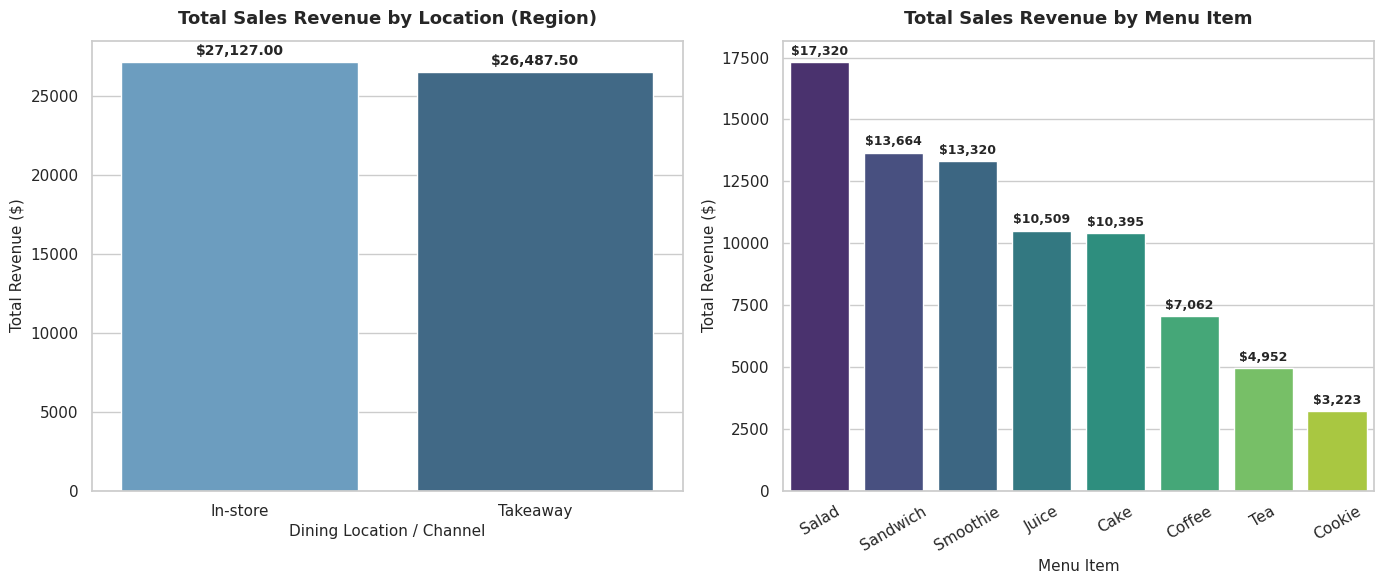

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling theme
sns.set_theme(style="whitegrid")

# Load the cleaned analysis dataset directly from the processed folder
df_cleaned_viz = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "cleaned_cafe_sales.csv")

# 1. Aggregate Sales by Location (Region)
location_summary = df_cleaned_viz.groupby('location').agg(
    total_sales=('total_spent', 'sum'),
    transaction_count=('transaction_id', 'count'),
    avg_order_value=('total_spent', 'mean')
).reset_index()

print("--- Sales by Location (Region) Summary ---")
display(location_summary)

# 2. Aggregate Sales by Menu Item (Product Insights)
item_summary = df_cleaned_viz.groupby('item').agg(
    total_sales=('total_spent', 'sum'),
    total_qty=('quantity', 'sum'),
    transaction_count=('transaction_id', 'count')
).reset_index().sort_values(by='total_sales', ascending=False)

print("\n--- Product Sales Summary ---")
display(item_summary)

# 3. Generate Publication-Quality Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Total Sales Revenue by Location (Region)
sns.barplot(data=location_summary, x='location', y='total_sales', ax=axes[0], palette='Blues_d')
axes[0].set_title('Total Sales Revenue by Location (Region)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Dining Location / Channel', fontsize=11)
axes[0].set_ylabel('Total Revenue ($)', fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f"${p.get_height():,.2f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3), textcoords='offset points')

# Plot 2: Total Sales Revenue by Menu Item
sns.barplot(data=item_summary, x='item', y='total_sales', ax=axes[1], palette='viridis')
axes[1].set_title('Total Sales Revenue by Menu Item', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Menu Item', fontsize=11)
axes[1].set_ylabel('Total Revenue ($)', fontsize=11)
axes[1].tick_params(axis='x', rotation=30)
for p in axes[1].patches:
    axes[1].annotate(f"${p.get_height():,.0f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

**Findings & Strategic Insights:**
- **Location/Region Analysis:** In-Store sales generated `$27,127.00 (3,017 transactions) and Takeaway generated $26,487.50 (3,022 transactions)`. Both channels show remarkably balanced performance in terms of volume and revenue. *(Note: ~39.6% of raw records lacked location data and were retained as explicit `NULL`s).*
- **Product Performance:** Higher-priced menu items (*Salad, Sandwich, Smoothie*) drive the largest share of total revenue, whereas high-frequency lower-priced items (*Coffee, Tea, Cookie*) drive steady transaction counts.